# Lista de exercícios — Gauss–Seidel
**Cálculo Numérico — Prof.ª Raquel Lobosco**

Sistema: $10x-y+2z=6$, $-x+11y-z=22$, $2x-y+10z=-10$. Aproximação inicial $(0,0,0)$; parada quando $\|\mathbf{x}^{(k)}-\mathbf{x}^{(k-1)}\|_\infty<10^{-5}$.

## 1. Forma matricial
$$A=\begin{bmatrix}10&-1&2\\-1&11&-1\\2&-1&10\end{bmatrix},\quad \mathbf{x}=\begin{bmatrix}x\\y\\z\end{bmatrix},\quad \mathbf{b}=\begin{bmatrix}6\\22\\-10\end{bmatrix}. $$
## 2. Dominância diagonal
Linha 1: $|10|=10>|-1|+|2|=3$; linha 2: $|11|=11>|-1|+|-1|=2$; linha 3: $|10|=10>|2|+|-1|=3$. Logo, $A$ é estritamente diagonalmente dominante por linhas, o que garante a convergência do método para qualquer chute inicial.
## 3. Fórmulas iterativas
$$x^{(k)}=\frac{6+y^{(k-1)}-2z^{(k-1)}}{10},\quady^{(k)}=\frac{22+x^{(k)}+z^{(k-1)}}{11},\quadz^{(k)}=\frac{-10-2x^{(k)}+y^{(k)}}{10}. $$
Cada equação usa imediatamente as componentes já atualizadas.

## 4. Três primeiras iterações
Com $\mathbf{x}^{(0)}=(0,0,0)$:

**$k=1$:** $x^{(1)}=(6+0-2\cdot0)/10=0,6$; $y^{(1)}=(22+0,6+0)/11=2,0545454545$; $z^{(1)}=(-10-2\cdot0,6+2,0545454545)/10=-0,9145454545$.

**$k=2$:** $x^{(2)}=(6+2,0545454545-2(-0,9145454545))/10=0,9883636364$; $y^{(2)}=(22+0,9883636364-0,9145454545)/11=2,0067107438$; $z^{(2)}=(-10-2(0,9883636364)+2,0067107438)/10=-0,9970016529$.

**$k=3$:** $x^{(3)}=(6+2,0067107438-2(-0,9970016529))/10=1,0000714050$; $y^{(3)}=(22+1,0000714050-0,9970016529)/11=2,0002790684$; $z^{(3)}=(-10-2(1,0000714050)+2,0002790684)/10=-0,9999863742$. Os valores exibidos são arredondados; os cálculos usam precisão completa.

## 5. Código Python

In [1]:
"""Resolução da lista de Gauss-Seidel da Prof.ª Raquel Lobosco.

Compatível com Python 3, Jupyter e Google Colab. Requer matplotlib apenas
para gerar os gráficos. Execute: python gauss_seidel.py
"""

from pathlib import Path

import matplotlib.pyplot as plt


TOLERANCIA = 1e-5
MAX_ITERACOES = 100


def gauss_seidel(tolerancia=TOLERANCIA, max_iteracoes=MAX_ITERACOES):
    """Devolve linhas (k, x, y, z, erro) até a primeira diferença < tolerância."""
    if tolerancia <= 0 or max_iteracoes < 1:
        raise ValueError("Use tolerância positiva e ao menos uma iteração.")

    x = y = z = 0.0
    linhas = [(0, x, y, z, None)]
    for k in range(1, max_iteracoes + 1):
        anterior = (x, y, z)
        x = (6 + y - 2 * z) / 10
        y = (22 + x + z) / 11
        z = (-10 - 2 * x + y) / 10
        erro = max(abs(atual - velho) for atual, velho in zip((x, y, z), anterior))
        linhas.append((k, x, y, z, erro))
        if erro < tolerancia:
            return linhas
    raise RuntimeError(f"Não convergiu em {max_iteracoes} iterações.")


def salvar_graficos(linhas, pasta=Path(".")):
    pasta = Path(pasta)
    pasta.mkdir(parents=True, exist_ok=True)
    ks = [linha[0] for linha in linhas]

    fig, ax = plt.subplots(figsize=(8, 4.8), layout="constrained")
    for indice, nome in ((1, "x"), (2, "y"), (3, "z")):
        ax.plot(ks, [linha[indice] for linha in linhas], marker="o", label=nome)
    ax.set(xlabel="Iteração k", ylabel="Aproximação", title="Gauss–Seidel: evolução das incógnitas")
    ax.set_xticks(ks)
    ax.grid(alpha=0.3)
    ax.legend()
    fig.savefig(pasta / "aproximacoes.png", dpi=180)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(8, 4.8), layout="constrained")
    ax.semilogy(ks[1:], [linha[4] for linha in linhas[1:]], marker="o")
    ax.axhline(TOLERANCIA, color="crimson", ls="--", label="tolerância = 10⁻⁵")
    ax.set(xlabel="Iteração k", ylabel="Norma infinito da diferença",
           title="Gauss–Seidel: erro entre iterações")
    ax.set_xticks(ks[1:])
    ax.grid(alpha=0.3, which="both")
    ax.legend()
    fig.savefig(pasta / "erro_log.png", dpi=180)
    plt.close(fig)




## 6. Tabela de iterações

In [2]:
linhas = gauss_seidel()
print(f"{'k':>2} {'x':>14} {'y':>14} {'z':>14} {'erro infinito':>16}")
for k, x, y, z, erro in linhas:
    e = f'{erro:.10e}' if erro is not None else '—'
    print(f'{k:2d} {x:14.10f} {y:14.10f} {z:14.10f} {e:>16}')
print(f'\nIterações: {len(linhas)-1}')
print(f'Solução aproximada: {linhas[-1][1:4]}')

 k              x              y              z    erro infinito
 0   0.0000000000   0.0000000000   0.0000000000                —
 1   0.6000000000   2.0545454545  -0.9145454545 2.0545454545e+00
 2   0.9883636364   2.0067107438  -0.9970016529 3.8836363636e-01
 3   1.0000714050   2.0002790684  -0.9999863742 1.1707768595e-02
 4   1.0000251817   2.0000035280  -1.0000046835 2.7554041391e-04
 5   1.0000012895   1.9999996915  -1.0000002888 2.3892164743e-05
 6   1.0000000269   1.9999999762  -1.0000000078 1.2626069386e-06

Iterações: 6
Solução aproximada: (1.0000000268962375, 1.9999999761946128, -1.0000000077597861)


## 7. Gráficos

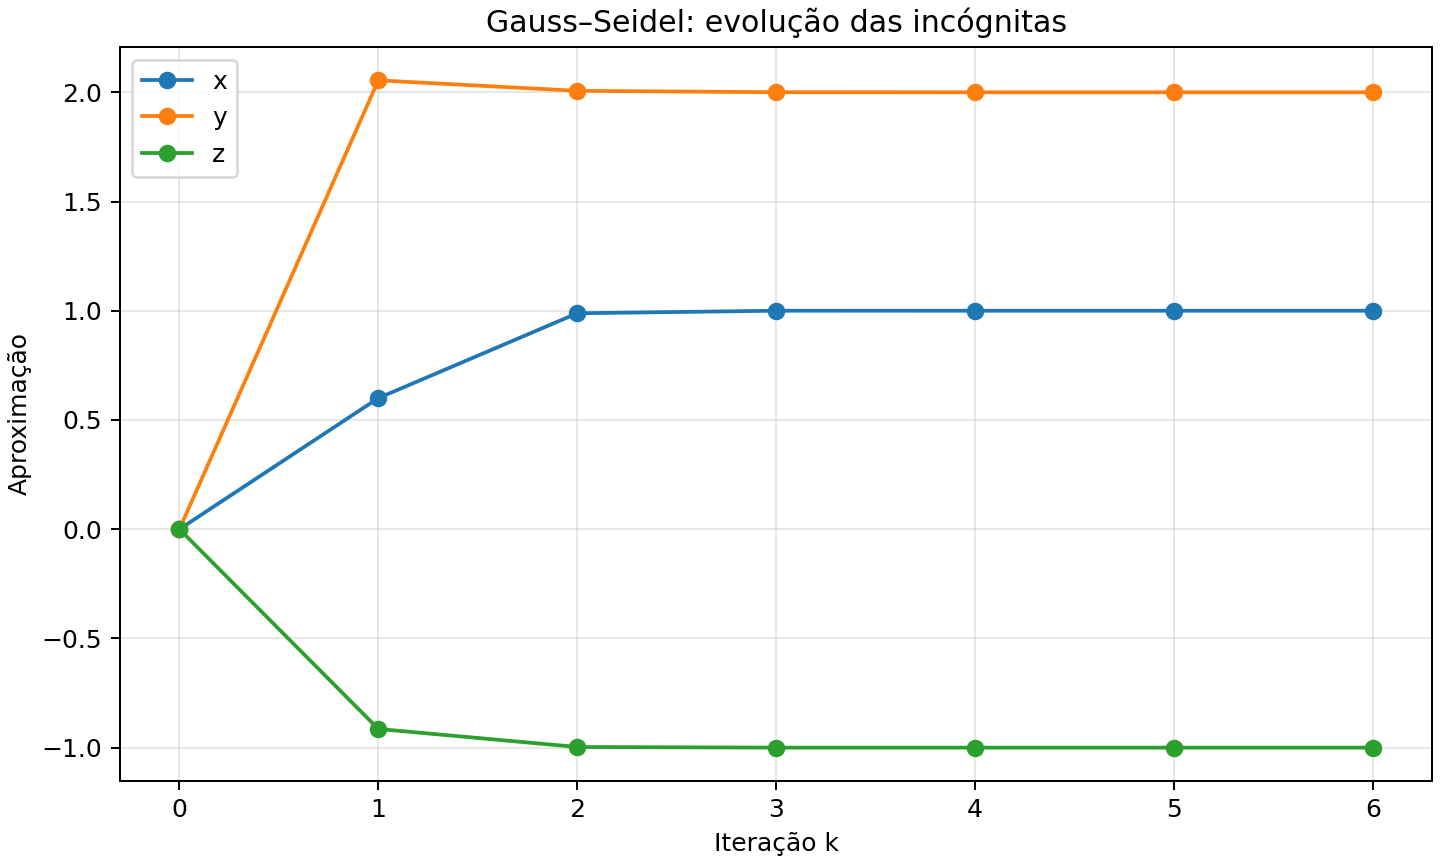

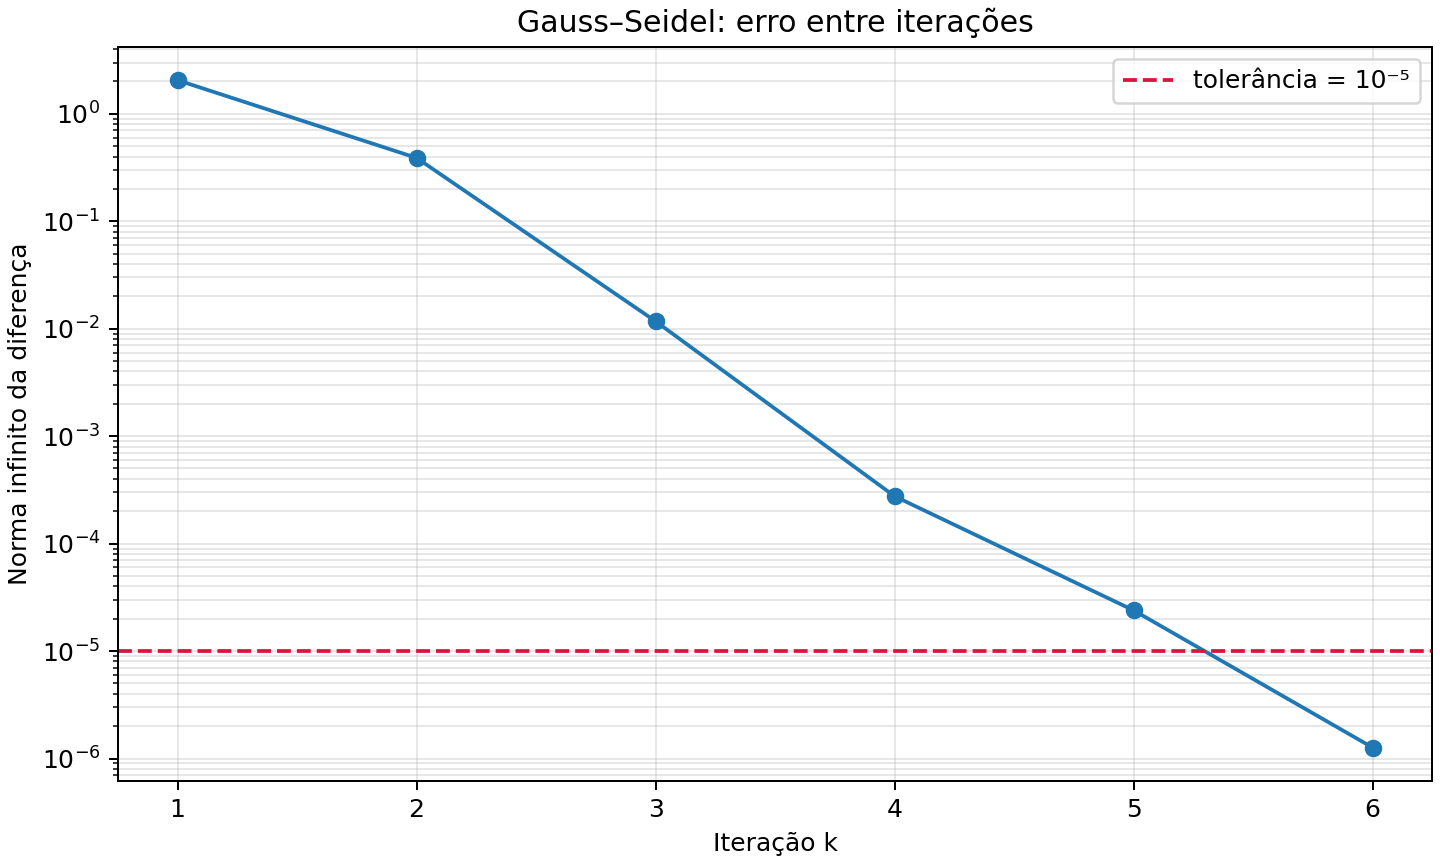

In [3]:
# Funciona no Colab e salva dois PNGs na pasta da sessão.
salvar_graficos(linhas)
from IPython.display import display, Image
display(Image(filename='aproximacoes.png'))
display(Image(filename='erro_log.png'))

## Conclusão
O critério estrito de parada é satisfeito em $k=6$, com solução aproximada $(1,0000000269; 1,9999999762; -1,0000000078)$. A solução exata $(1,2,-1)$ confirma o resultado.